In [ ]:
import os
import shutil

# Create kaggle directory
os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)


In [ ]:
!pip install torch torchvision scikit-learn

In [ ]:
pip install grad-cam

In [ ]:
!apt update && apt install -y libgl1

In [ ]:
# Move kaggle.json to the proper location (assuming you uploaded to current working dir)
shutil.move("kaggle.json", os.path.expanduser("~/.kaggle/kaggle.json"))

# Set permissions (required by Kaggle)
os.chmod(os.path.expanduser("~/.kaggle/kaggle.json"), 0o600)

In [ ]:
!pip install kaggle

In [ ]:
!apt-get update && apt-get install -y unzip

In [ ]:
!kaggle datasets download -d imrankhan77/nct-crc-he-100k

Dataset URL: https://www.kaggle.com/datasets/imrankhan77/nct-crc-he-100k
License(s): CC0-1.0
 99%|█████████████████████████████████████▌| 11.1G/11.2G [00:05<00:00, 2.20GB/s]
100%|██████████████████████████████████████| 11.2G/11.2G [00:05<00:00, 2.19GB/s]


In [ ]:
!kaggle datasets download -d andrewmvd/lung-and-colon-cancer-histopathological-images

Dataset URL: https://www.kaggle.com/datasets/andrewmvd/lung-and-colon-cancer-histopathological-images
License(s): CC-BY-SA-4.0
 95%|████████████████████████████████████▏ | 1.68G/1.76G [00:00<00:00, 2.24GB/s]
100%|██████████████████████████████████████| 1.76G/1.76G [00:00<00:00, 2.24GB/s]


In [ ]:
!kaggle datasets download -d imrankhan77/crc-val-he-7k

Dataset URL: https://www.kaggle.com/datasets/imrankhan77/crc-val-he-7k
License(s): CC0-1.0
 79%|███████████████████████████████▋        | 624M/787M [00:00<00:00, 2.18GB/s]
100%|████████████████████████████████████████| 787M/787M [00:00<00:00, 2.18GB/s]


In [ ]:
!unzip /workspace/SD/lung-and-colon-cancer-histopathological-images.zip -d /workspace/SD/lung-and-colon-cancer-histopathological-images

In [ ]:
!unzip /workspace/SD/nct-crc-he-100k.zip -d /workspace/SD/NCT-CRC-HE-100K

In [ ]:
!unzip /workspace/SD/crc-val-he-7k.zip -d /workspace/SD/crc-val-he-7k

In [ ]:
import os
import torch
from torch import nn
from torch.utils.data import DataLoader, SubsetRandomSampler
from torchvision import datasets, transforms
from torchvision.models import swin_t, Swin_T_Weights
from sklearn.model_selection import train_test_split

In [ ]:
# -------- Fast boot flags (Kaggle) --------
FAST_BOOT = True  # True = skip plotting and heavy scans on every run
CACHE_COUNTS = '/kaggle/working/class_counts.npz'

import os, gc, time
from pathlib import Path


train_dir_9 = Path('/workspace/SD/NCT-CRC-HE-100K/NCT-CRC-HE-100K')
val_dir_9   = Path('/workspace/SD/crc-val-he-7k/CRC-VAL-HE-7K')  # use if validating on CRC-VAL-HE-7K
lc_dir_2    = Path('/workspace/SD/lung-and-colon-cancer-histopathological-images/lung_colon_image_set/colon_image_sets')

classes_9 = ['ADI','BACK','DEB','LYM','MUC','MUS','NORM','STR','TUM']
classes_2 = ['colon_aca','colon_n']

counts_9 = counts_2 = None

# Load cached counts if present
try:
    import numpy as np
    if Path(CACHE_COUNTS).exists():
        z = np.load(CACHE_COUNTS)
        counts_9 = z['counts_9'].tolist()
        counts_2 = z['counts_2'].tolist()
except Exception:
    pass

def fast_count(root: Path, class_names):
    out = []
    for cname in class_names:
        d = root / cname
        if not d.exists():
            out.append(0); continue
        # scandir is faster than listdir; we do NOT open images
        with os.scandir(d) as it:
            out.append(sum(1 for _ in it))
    return out

if counts_9 is None or counts_2 is None:
    counts_9 = fast_count(train_dir_9, classes_9)
    counts_2 = fast_count(lc_dir_2, classes_2)
    try:
        np.savez_compressed(CACHE_COUNTS, counts_9=np.array(counts_9), counts_2=np.array(counts_2))
    except Exception:
        pass

print("Counts (cached):")
print("  9-class NCT-CRC-HE-100K:", dict(zip(classes_9, counts_9)))
print("  2-class LC colon subset:", dict(zip(classes_2, counts_2)))

# Optional plot (off in FAST_BOOT)
if not FAST_BOOT:
    import numpy as np, matplotlib.pyplot as plt
    fig, axs = plt.subplots(1,2, figsize=(12,4))
    x = np.arange(len(classes_9))
    axs[0].bar(x, counts_9); axs[0].set_xticks(x)
    axs[0].set_xticklabels(classes_9, rotation=45, ha='right')
    axs[0].set_title('NCT-CRC-HE-100K (9-class)')
    x2 = np.arange(len(classes_2))
    axs[1].bar(x2, counts_2); axs[1].set_xticks(x2)
    axs[1].set_xticklabels(classes_2)
    axs[1].set_title('LC25000 (2-class)')
    plt.tight_layout(); plt.show()


Counts (cached):
  9-class NCT-CRC-HE-100K: {'ADI': 10407, 'BACK': 10566, 'DEB': 11512, 'LYM': 11557, 'MUC': 8896, 'MUS': 13536, 'NORM': 8763, 'STR': 10446, 'TUM': 14317}
  2-class LC colon subset: {'colon_aca': 5000, 'colon_n': 5000}


In [ ]:
# Global run flags (so you can keep structure but skip heavy sections quickly)
USE_FAST_TRAIN = True   # use optimized training (warm-up + AMP + early stop)
RUN_LC25000    = False  # set True to run the 2-class training in this session

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

### Training for 9-Class Datasets (NCT as train, CRC as test/val)
# Load datasets (expects train_dir_9 and val_dir_9 defined earlier)
train_ds_9 = datasets.ImageFolder(train_dir_9, transform=transform)
val_ds_9   = datasets.ImageFolder(val_dir_9,   transform=transform)

# Data loaders (single-line args to avoid indentation issues)
cpu_workers = max(2, os.cpu_count() - 2)
train_loader_9 = DataLoader(train_ds_9, batch_size=128, shuffle=True,
                            num_workers=cpu_workers, pin_memory=True,
                            persistent_workers=True, prefetch_factor=4)
val_loader_9   = DataLoader(val_ds_9, batch_size=128, shuffle=False,
                            num_workers=cpu_workers, pin_memory=True,
                            persistent_workers=True, prefetch_factor=4)

In [ ]:
# Data transforms (common for both datasets)
transform = transforms.Compose([
    transforms.Resize(224),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# ----------------------------
# Early Stopping class (same API as before)
class EarlyStopping:
    def __init__(self, patience=5, min_epochs=12, delta=0.001):
        self.patience = patience
        self.min_epochs = min_epochs
        self.delta = delta
        self.best_loss = float('inf')
        self.counter = 0
        self.epoch = 0

    def __call__(self, val_loss):
        self.epoch += 1
        improved = val_loss < self.best_loss - self.delta
        if improved:
            self.best_loss = val_loss
            self.counter = 0
        else:
            self.counter += 1
        return self.epoch >= self.min_epochs and self.counter >= self.patience




# Model setup
weights = Swin_T_Weights.IMAGENET1K_V1
model_9 = swin_t(weights=weights)
model_9.head = nn.Linear(model_9.head.in_features, 9)
model_9.to(device)

# Optimizer and loss
optimizer_9 = torch.optim.AdamW(model_9.parameters(), lr=1e-4)
criterion = nn.CrossEntropyLoss()

# Early stopping
early_stopping_9 = EarlyStopping(patience=5, min_epochs=12)

# Training loop
history_9 = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
best_val_9 = float('inf')
best_state_9 = None
for epoch in range(100):  # Max epochs
    model_9.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0
    for inputs, labels in train_loader_9:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer_9.zero_grad()
        outputs = model_9(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer_9.step()
        train_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        train_total += labels.size(0)
        train_correct += predicted.eq(labels).sum().item()
    train_loss /= max(1, train_total)
    train_acc = train_correct / max(1, train_total)

    model_9.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0
    with torch.no_grad():
        for inputs, labels in val_loader_9:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model_9(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            val_total += labels.size(0)
            val_correct += predicted.eq(labels).sum().item()
    val_loss /= max(1, val_total)
    val_acc = val_correct / max(1, val_total)

    # --- these lines belong inside the loop ---
    history_9['train_loss'].append(train_loss)
    history_9['train_acc'].append(train_acc)
    history_9['val_loss'].append(val_loss if 'val_loss' in locals() else test_loss)
    history_9['val_acc'].append(val_acc if 'val_acc' in locals() else test_acc)
    if ('val_loss' in locals() and val_loss < best_val_9) or ('test_loss' in locals() and test_loss < best_val_9):
        best_val_9 = (val_loss if 'val_loss' in locals() else test_loss)
        best_state_9 = {'model_state': model_9.state_dict()}

    print(f"9-Class Epoch {epoch+1}: Train Loss: {train_loss:.4f}, "
          f"Train Acc: {train_acc:.4f}, Val Loss: {val_loss:.4f}, "
          f"Val Acc: {val_acc:.4f}")

    if early_stopping_9(val_loss):
        print("Early stopping for 9-class model")
        break


In [ ]:
# --- Save trained model_9 (final and best, if available) ---
import os
# os.makedirs('/kaggle/working', exist_ok=True)
final_ckpt_path_9 = f'/workspace/SD/model_9_final.pth'
torch.save({'model_state': model_9.state_dict(),
            'class_to_idx': (train_ds_9.class_to_idx if 'train_ds_9' in globals() else None),
            'arch': 'swin_t'}, final_ckpt_path_9)
print(f'Saved final model to {final_ckpt_path_9}')

if best_state_9 is not None:
    best_ckpt_path_9 = f'/workspace/SD/model_9_best.pth'
    best_payload_9 = best_state_9
    best_payload_9['class_to_idx'] = (train_ds_9.class_to_idx if 'train_ds_9' in globals() else None)
    best_payload_9['arch'] = 'swin_t'
    torch.save(best_payload_9, best_ckpt_path_9)
    print(f'Saved best model (by val/test loss) to {best_ckpt_path_9}')

Saved final model to /workspace/SD/model_9_final.pth
Saved best model (by val/test loss) to /workspace/SD/model_9_best.pth


In [ ]:
### Training for 2-Class Dataset (LC25000 colon subset, with 80/20 train/test split)

# --- Minimal self-contained imports / fallbacks (keeps your logic the same) ---
import os, glob
from pathlib import Path
import torch
from torch import nn
from torch.utils.data import DataLoader, SubsetRandomSampler
from torchvision import datasets, transforms
from torchvision.models import swin_t, Swin_T_Weights
from sklearn.model_selection import train_test_split

# Fallbacks only if previous cells weren't run
device = globals().get('device', torch.device('cuda' if torch.cuda.is_available() else 'cpu'))
cpu_workers = globals().get('cpu_workers', max(2, os.cpu_count() - 2))
weights = globals().get('weights', Swin_T_Weights.IMAGENET1K_V1)
criterion = globals().get('criterion', nn.CrossEntropyLoss())
if 'transform' not in globals():
    transform = transforms.Compose([
        transforms.Resize(224),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                             std=[0.229, 0.224, 0.225])
    ])
if 'EarlyStopping' not in globals():
    class EarlyStopping:
        def __init__(self, patience=5, min_epochs=12, delta=0.001):
            self.patience = patience
            self.min_epochs = min_epochs
            self.delta = delta
            self.best_loss = float('inf')
            self.counter = 0
            self.epoch = 0
        def __call__(self, val_loss):
            self.epoch += 1
            improved = val_loss < self.best_loss - self.delta
            if improved:
                self.best_loss = val_loss
                self.counter = 0
            else:
                self.counter += 1
            return self.epoch >= self.min_epochs and self.counter >= self.patience

# # ---- Resolve lc_dir_2 if it's missing ----
# def find_lc25000_colon_root() -> Path | None:
#     # Common default
#     p = Path('/workspace/SD/lung-and-colon-cancer-histopathological-imageslung_colon_image_set/colon_image_sets')
#     if (p / 'colon_aca').exists() and (p / 'colon_n').exists():
#         return p
#     # Search for colon_aca with sibling colon_n
#     for path in glob.glob('/kaggle/input/**/colon_aca', recursive=True):
#         parent = Path(path).parent
#         if (parent / 'colon_n').exists():
#             return parent
#     # Search for a folder literally named 'colon' with both classes
#     for path in glob.glob('/kaggle/input/**/colon', recursive=True):
#         parent = Path(path)
#         if (parent / 'colon_aca').exists() and (parent / 'colon_n').exists():
#             return parent
#     return None

# if 'lc_dir_2' not in globals() or not Path(globals().get('lc_dir_2', '')).exists():
#     _auto = find_lc25000_colon_root()
#     if _auto is None:
#         raise RuntimeError(
#             "lc_dir_2 is not defined and LC25000 colon subset was not found under /kaggle/input.\n"
#             "Please set lc_dir_2 to the folder containing 'colon_aca' and 'colon_n'."
#         )
#     lc_dir_2 = str(_auto)  # set for this cell/environment

# Load dataset (expects lc_dir_2 defined and valid)
lc_ds_2 = datasets.ImageFolder(lc_dir_2, transform=transform)

# Stratified split (80% train, 20% test)
indices = list(range(len(lc_ds_2)))
train_idx, test_idx = train_test_split(indices, test_size=0.2,
                                       stratify=lc_ds_2.targets, random_state=42)

# Samplers and loaders
train_sampler = SubsetRandomSampler(train_idx)
test_sampler  = SubsetRandomSampler(test_idx)
train_loader_2 = DataLoader(lc_ds_2, batch_size=128, sampler=train_sampler,
                            num_workers=cpu_workers, pin_memory=True,
                            persistent_workers=True, prefetch_factor=4)
test_loader_2  = DataLoader(lc_ds_2, batch_size=128, sampler=test_sampler,
                            num_workers=cpu_workers, pin_memory=True,
                            persistent_workers=True, prefetch_factor=4)

# Model setup
model_2 = swin_t(weights=weights)
model_2.head = nn.Linear(model_2.head.in_features, 2)
model_2.to(device)

# Optimizer and loss
optimizer_2 = torch.optim.AdamW(model_2.parameters(), lr=1e-4)

# Early stopping
early_stopping_2 = EarlyStopping(patience=5, min_epochs=12)

# Training loop (similar to 9-class, using test set as val)
history_2 = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
best_val_2 = float('inf')
best_state_2 = None
for epoch in range(100):  # Max epochs
    model_2.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0
    for inputs, labels in train_loader_2:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer_2.zero_grad()
        outputs = model_2(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer_2.step()
        train_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        train_total += labels.size(0)
        train_correct += predicted.eq(labels).sum().item()
    train_loss /= max(1, train_total)
    train_acc = train_correct / max(1, train_total)

    model_2.eval()
    test_loss = 0.0
    test_correct = 0
    test_total = 0
    with torch.no_grad():
        for inputs, labels in test_loader_2:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model_2(inputs)
            loss = criterion(outputs, labels)
            test_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            test_total += labels.size(0)
            test_correct += predicted.eq(labels).sum().item()
    test_loss /= max(1, test_total)
    test_acc = test_correct / max(1, test_total)

    # keep these updates inside the loop
    history_2['train_loss'].append(train_loss)
    history_2['train_acc'].append(train_acc)
    history_2['val_loss'].append(test_loss)  # using test split as val
    history_2['val_acc'].append(test_acc)
    if test_loss < best_val_2:
        best_val_2 = test_loss
        best_state_2 = {'model_state': model_2.state_dict()}

    print(f"2-Class Epoch {epoch+1}: Train Loss: {train_loss:.4f}, "
          f"Train Acc: {train_acc:.4f}, Test Loss: {test_loss:.4f}, "
          f"Test Acc: {test_acc:.4f}")

    if early_stopping_2(test_loss):
        print("Early stopping for 2-class model")
        break

# --- Save trained model_2 (final and best, if available) ---
# os.makedirs('/kaggle/working', exist_ok=True)
final_ckpt_path_2 = f'/workspace/SD/model_2_final.pth'
torch.save({'model_state': model_2.state_dict(),
            'class_to_idx': (lc_ds_2.class_to_idx if 'lc_ds_2' in globals() else None),
            'arch': 'swin_t'}, final_ckpt_path_2)
print(f'Saved final model to {final_ckpt_path_2}')

if best_state_2 is not None:
    best_ckpt_path_2 = f'/workspace/SD/model_2_best.pth'
    best_payload_2 = best_state_2
    best_payload_2['class_to_idx'] = (lc_ds_2.class_to_idx if 'lc_ds_2' in globals() else None)
    best_payload_2['arch'] = 'swin_t'
    torch.save(best_payload_2, best_ckpt_path_2)
    print(f'Saved best model (by val/test loss) to {best_ckpt_path_2}')


2-Class Epoch 1: Train Loss: 0.0445, Train Acc: 0.9802, Test Loss: 0.0042, Test Acc: 0.9985
2-Class Epoch 2: Train Loss: 0.0059, Train Acc: 0.9982, Test Loss: 0.0007, Test Acc: 0.9995
2-Class Epoch 3: Train Loss: 0.0077, Train Acc: 0.9979, Test Loss: 0.0007, Test Acc: 0.9995
2-Class Epoch 4: Train Loss: 0.0005, Train Acc: 0.9998, Test Loss: 0.0000, Test Acc: 1.0000
2-Class Epoch 5: Train Loss: 0.0001, Train Acc: 1.0000, Test Loss: 0.0000, Test Acc: 1.0000
2-Class Epoch 6: Train Loss: 0.0001, Train Acc: 1.0000, Test Loss: 0.0000, Test Acc: 1.0000
2-Class Epoch 7: Train Loss: 0.0000, Train Acc: 1.0000, Test Loss: 0.0000, Test Acc: 1.0000
2-Class Epoch 8: Train Loss: 0.0002, Train Acc: 0.9999, Test Loss: 0.0000, Test Acc: 1.0000
2-Class Epoch 9: Train Loss: 0.0124, Train Acc: 0.9951, Test Loss: 0.0039, Test Acc: 0.9990
2-Class Epoch 10: Train Loss: 0.0008, Train Acc: 0.9999, Test Loss: 0.0005, Test Acc: 0.9995
2-Class Epoch 11: Train Loss: 0.0007, Train Acc: 0.9999, Test Loss: 0.0005, Tes

In [ ]:
# import os, torch
# from torch.utils.data import DataLoader
# from torchvision import datasets
# from torchvision.models import Swin_T_Weights

# # Use the pretrained transforms for Swin-T
# weights = Swin_T_Weights.IMAGENET1K_V1
# transform = weights.transforms()

# # Datasets (use the paths from the FAST_BOOT cell)
# train_ds_9 = datasets.ImageFolder(train_dir_9, transform=transform)
# val_ds_9   = datasets.ImageFolder(val_dir_9,   transform=transform)

# cpu_workers = max(2, os.cpu_count() - 2)
# loader_args = dict(
#     batch_size=128,                 # if OOM on P100 (16GB), lower to 48/32
#     num_workers=cpu_workers,
#     pin_memory=True,
#     persistent_workers=True,
#     prefetch_factor=4
# )

# train_loader_9 = DataLoader(train_ds_9, shuffle=True,  **loader_args)
# val_loader_9   = DataLoader(val_ds_9,   shuffle=False, **loader_args)


In [ ]:
# import torch
# from torch import nn, optim
# from torchvision.models import swin_t, Swin_T_Weights

# device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# torch.backends.cudnn.benchmark = True  # stable input size improves speed

# NUM_CLASSES_9 = 9

# weights = Swin_T_Weights.IMAGENET1K_V1
# model_9 = swin_t(weights=weights)
# model_9.head = nn.Linear(model_9.head.in_features, NUM_CLASSES_9)
# model_9 = model_9.to(device).to(memory_format=torch.channels_last)

# criterion = nn.CrossEntropyLoss()
# optimizer = optim.AdamW(model_9.parameters(), lr=3e-4, weight_decay=0.05)

# # AMP scaler (helps memory on P100; speedup is moderate but useful)
# scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())

# def run_epoch(model, loader, train=True, accum_steps=1):
#     if train:
#         model.train()
#     else:
#         model.eval()
#     total, correct, loss_sum = 0, 0, 0.0
#     if train:
#         optimizer.zero_grad(set_to_none=True)
#     for step, (x, y) in enumerate(loader):
#         x = x.to(device, non_blocking=True).to(memory_format=torch.channels_last)
#         y = y.to(device, non_blocking=True)
#         with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
#             logits = model(x)
#             loss = criterion(logits, y)
#             if train:
#                 loss = loss / accum_steps
#         if train:
#             scaler.scale(loss).backward()
#             if (step + 1) % accum_steps == 0:
#                 scaler.step(optimizer); scaler.update()
#                 optimizer.zero_grad(set_to_none=True)
#         loss_sum += loss.detach().item() * (accum_steps if train else 1) * x.size(0)
#         pred = logits.argmax(1); correct += (pred == y).sum().item()
#         total += x.size(0)
#     return loss_sum / max(1,total), correct / max(1,total)


In [ ]:
# # Fast training schedule tuned for Kaggle P100
# MAX_EPOCHS     = 50
# WARMUP_EPOCHS  = 2
# PATIENCE       = 5
# MIN_EPOCHS     = 12

# if USE_FAST_TRAIN:
#     # --- Warm-up: train just the head for 1–2 epochs ---
#     for p in model_9.parameters(): p.requires_grad = False
#     for p in model_9.head.parameters(): p.requires_grad = True

#     history_9 = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
# best_val_9 = float('inf')
# best_state_9 = None
# for epoch in range(WARMUP_EPOCHS):
#         tr_loss, tr_acc = run_epoch(model_9, train_loader_9, train=True,  accum_steps=1)
#         va_loss, va_acc = run_epoch(model_9, val_loader_9,   train=False, accum_steps=1)
#         print(f"[Head] Epoch {epoch+1}/{WARMUP_EPOCHS}  tr_loss={tr_loss:.4f} tr_acc={tr_acc:.3f}  val_loss={va_loss:.4f} val_acc={va_acc:.3f}")

#     # --- Unfreeze all and continue with early stopping ---
#     for p in model_9.parameters(): p.requires_grad = True

#     # Gradient accumulation to simulate larger effective batch on P100 16GB
#     BATCH_SIZE = train_loader_9.batch_size
#     EFFECTIVE  = 128
#     ACCUM      = max(1, EFFECTIVE // BATCH_SIZE)

#     best_val = float('inf'); bad = 0
#     for epoch in range(MAX_EPOCHS - WARMUP_EPOCHS):
#         tr_loss, tr_acc = run_epoch(model_9, train_loader_9, train=True,  accum_steps=ACCUM)
#         va_loss, va_acc = run_epoch(model_9, val_loader_9,   train=False, accum_steps=1)
#         print(f"[Full] Epoch {epoch+1}  tr_loss={tr_loss:.4f} tr_acc={tr_acc:.3f}  val_loss={va_loss:.4f} val_acc={va_acc:.3f}")

#         if epoch + 1 >= MIN_EPOCHS:
#             if va_loss + 1e-6 < best_val:
#                 best_val = va_loss; bad = 0
#             else:
#                 bad += 1
#                 if bad >= PATIENCE:
#                     print("Early stopping.")
#                     break
# else:
#     # If you want to keep the original loop structure, make sure to lower epochs from 100 to ~12
#     pass

# # --- Save trained model_9 (final and best, if available) ---
# import os
# os.makedirs('/kaggle/working', exist_ok=True)
# final_ckpt_path_9 = f'/kaggle/working/model_9_final.pth'
# torch.save({'model_state': model_9.state_dict(), 'class_to_idx': (train_ds_9.class_to_idx if 'train_ds_9' in globals() else None), 'arch': 'swin_t'}, final_ckpt_path_9)
# print(f'Saved final model to {final_ckpt_path_9}')

# if best_state_9 is not None:
#     best_ckpt_path_9 = f'/kaggle/working/model_9_best.pth'
#     best_payload_9 = best_state_9
#     best_payload_9['class_to_idx'] = (train_ds_9.class_to_idx if 'train_ds_9' in globals() else None)
#     best_payload_9['arch'] = 'swin_t'
#     torch.save(best_payload_9, best_ckpt_path_9)
#     print(f'Saved best model (by val/test loss) to {best_ckpt_path_9}')


In [ ]:
# # Optional: 2-class training for LC25000 (off by default to keep runs short)
# if RUN_LC25000:
#     from torchvision.models import swin_t
#     from torchvision import datasets
#     from torch.utils.data import DataLoader
#     NUM_CLASSES_2 = 2
#     model_2 = swin_t(weights=Swin_T_Weights.IMAGENET1K_V1)
#     model_2.head = nn.Linear(model_2.head.in_features, NUM_CLASSES_2)
#     model_2 = model_2.to(device).to(memory_format=torch.channels_last)
#     opt2 = optim.AdamW(model_2.parameters(), lr=3e-4, weight_decay=0.05)
#     crit2 = nn.CrossEntropyLoss()
#     scaler2 = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())

#     # build datasets/dataloaders for LC25000 colon subset
#     ds2_train = datasets.ImageFolder(lc_dir_2, transform=transform)
#     dl2 = DataLoader(ds2_train, shuffle=True, **loader_args)

#     def run_epoch2(model, loader, train=True, accum_steps=1):
#         if train: model.train()
#         else: model.eval()
#         total, correct, loss_sum = 0, 0, 0.0
#         if train: opt2.zero_grad(set_to_none=True)
#         for step, (x, y) in enumerate(loader):
#             x = x.to(device, non_blocking=True).to(memory_format=torch.channels_last)
#             y = y.to(device, non_blocking=True)
#             with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
#                 logits = model(x)
#                 loss = crit2(logits, y)
#                 if train: loss = loss / accum_steps
#             if train:
#                 scaler2.scale(loss).backward()
#                 if (step + 1) % accum_steps == 0:
#                     scaler2.step(opt2); scaler2.update()
#                     opt2.zero_grad(set_to_none=True)
#             loss_sum += loss.detach().item() * (accum_steps if train else 1) * x.size(0)
#             pred = logits.argmax(1); correct += (pred == y).sum().item()
#             total += x.size(0)
#         return loss_sum / max(1,total), correct / max(1,total)

#     # short run
#     for ep in range(6):
#         tr_loss, tr_acc = run_epoch2(model_2, dl2, train=True, accum_steps=1)
#         print(f"[LC2] Epoch {ep+1}/6  tr_loss={tr_loss:.4f} tr_acc={tr_acc:.3f}")



=== Final 9-Class Validation Metrics ===
Loss: 0.2444  Acc: 0.9625
Classification report (9-class):
               precision    recall  f1-score   support

           0     1.0000    0.9963    0.9981      1338
           1     1.0000    1.0000    1.0000       847
           2     0.8921    1.0000    0.9430       339
           3     0.9709    1.0000    0.9852       634
           4     0.9951    0.9884    0.9918      1035
           5     0.8768    0.9139    0.8950       592
           6     0.9179    0.9811    0.9485       741
           7     0.8483    0.6508    0.7366       421
           8     0.9884    0.9676    0.9779      1233

    accuracy                         0.9625      7180
   macro avg     0.9433    0.9442    0.9418      7180
weighted avg     0.9621    0.9625    0.9612      7180



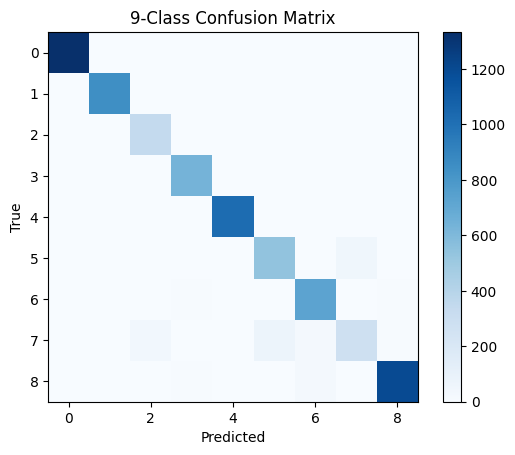

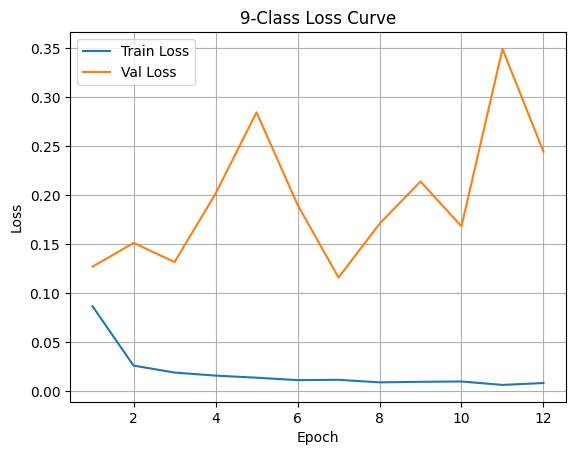


=== Final 2-Class Test Metrics ===
Loss: 0.0002  Acc: 1.0000
Classification report (2-class):
               precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000      1000
           1     1.0000    1.0000    1.0000      1000

    accuracy                         1.0000      2000
   macro avg     1.0000    1.0000    1.0000      2000
weighted avg     1.0000    1.0000    1.0000      2000



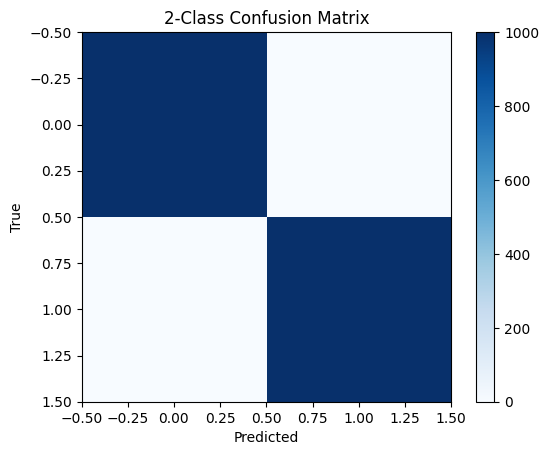

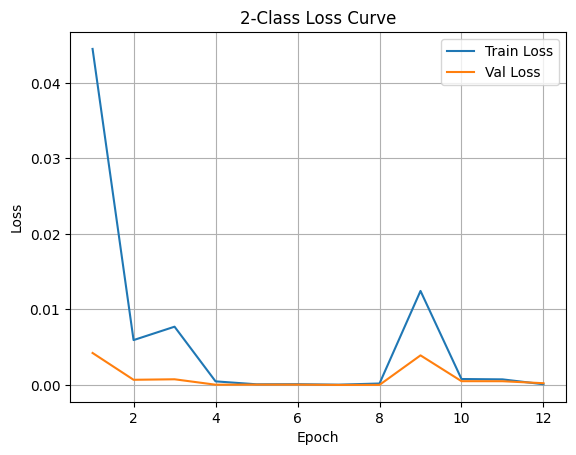

In [ ]:
# === Evaluation & Plots (final metrics, confusion matrix, curves) ===
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

def evaluate_model(model, loader, device):
    model.eval()
    total, correct = 0, 0
    losses = []
    y_true, y_pred = [], []
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)
            logits = model(x)
            loss = criterion(logits, y)
            losses.append(loss.item() * x.size(0))
            pred = logits.argmax(1)
            correct += (pred == y).sum().item()
            total += x.size(0)
            y_true.extend(y.detach().cpu().numpy().tolist())
            y_pred.extend(pred.detach().cpu().numpy().tolist())
    avg_loss = float(np.sum(losses)) / max(1, total)
    acc = correct / max(1, total)
    cm = confusion_matrix(y_true, y_pred)
    report = classification_report(y_true, y_pred, digits=4)
    return avg_loss, acc, cm, report

def plot_loss_curves(history, title_prefix=""):
    if not history or not history.get('train_loss'):
        print(f"{title_prefix}No history found to plot."); return
    import numpy as np
    import matplotlib.pyplot as plt
    xs = np.arange(1, len(history['train_loss'])+1)
    plt.figure()
    plt.plot(xs, history['train_loss'], label='Train Loss')
    plt.plot(xs, history['val_loss'],   label='Val Loss')
    plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.title(f'{title_prefix}Loss Curve')
    plt.legend(); plt.grid(True); plt.show()

# Evaluate 9-class on validation loader if available
if 'model_9' in globals() and 'val_loader_9' in globals():
    val_loss_9, val_acc_9, cm9, rep9 = evaluate_model(model_9, val_loader_9, device)
    print(f"\n=== Final 9-Class Validation Metrics ===\nLoss: {val_loss_9:.4f}  Acc: {val_acc_9:.4f}")
    print("Classification report (9-class):\n", rep9)
    plt.figure()
    plt.imshow(cm9, interpolation='nearest', cmap='Blues')
    plt.title('9-Class Confusion Matrix'); plt.colorbar()
    plt.xlabel('Predicted'); plt.ylabel('True')
    plt.show()
    if 'history_9' in globals():
        plot_loss_curves(history_9, title_prefix="9-Class ")

# Evaluate 2-class on test loader if available
if 'model_2' in globals() and 'test_loader_2' in globals():
    test_loss_2, test_acc_2, cm2, rep2 = evaluate_model(model_2, test_loader_2, device)
    print(f"\n=== Final 2-Class Test Metrics ===\nLoss: {test_loss_2:.4f}  Acc: {test_acc_2:.4f}")
    print("Classification report (2-class):\n", rep2)
    plt.figure()
    plt.imshow(cm2, interpolation='nearest', cmap='Blues')
    plt.title('2-Class Confusion Matrix'); plt.colorbar()
    plt.xlabel('Predicted'); plt.ylabel('True')
    plt.show()
    if 'history_2' in globals():
        plot_loss_curves(history_2, title_prefix="2-Class ")


Using device: cuda
Model loaded successfully
Dataset loaded with 7180 images


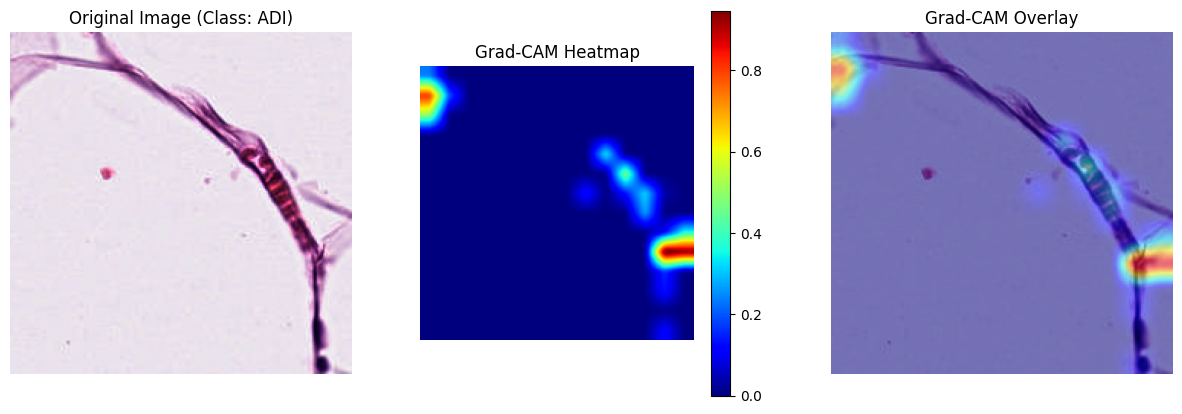

Grad-CAM for class ADI saved to gradcam_outputs/gradcam_class_ADI.png


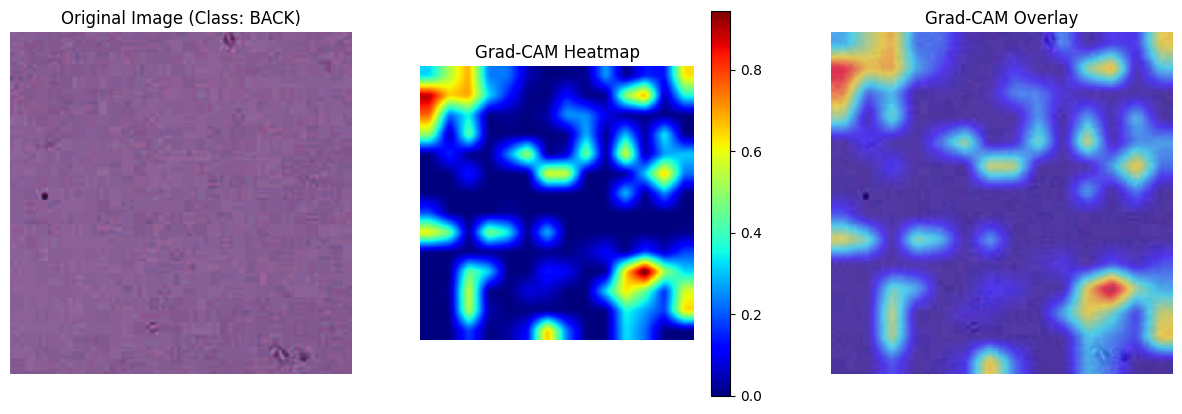

Grad-CAM for class BACK saved to gradcam_outputs/gradcam_class_BACK.png


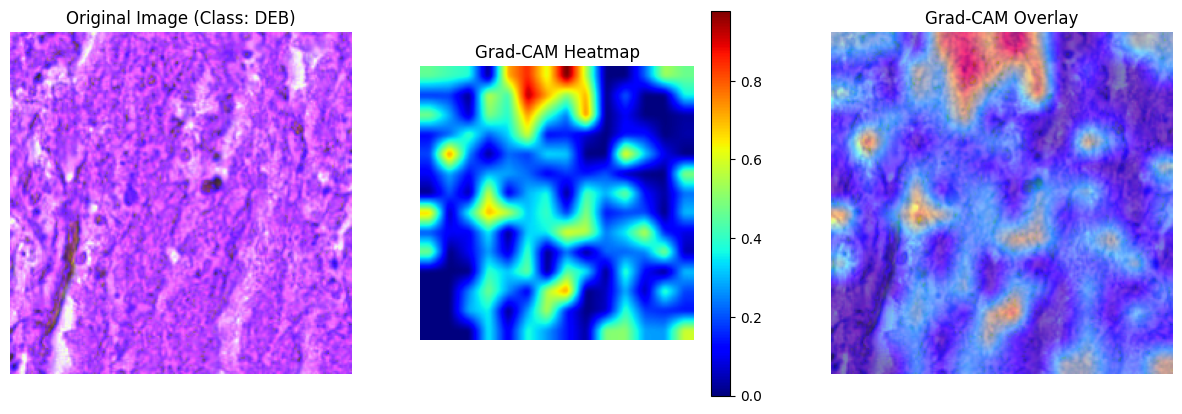

Grad-CAM for class DEB saved to gradcam_outputs/gradcam_class_DEB.png


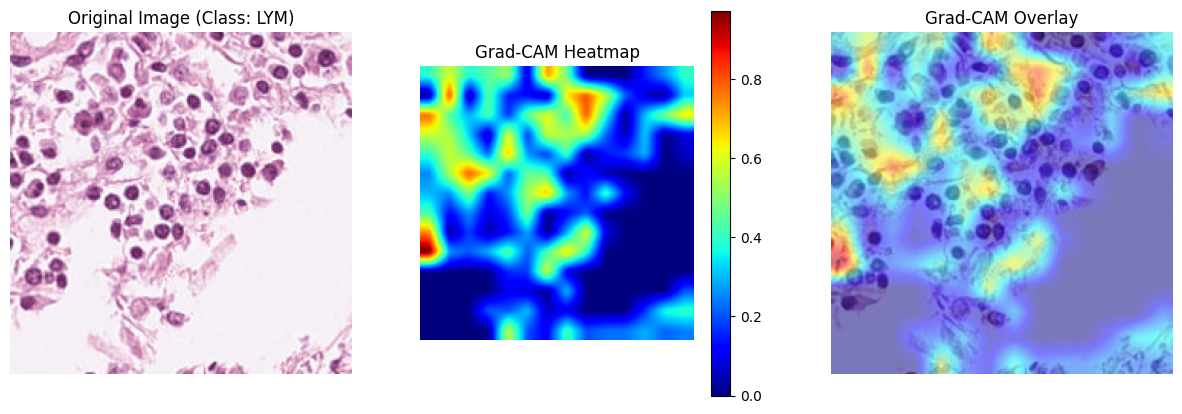

Grad-CAM for class LYM saved to gradcam_outputs/gradcam_class_LYM.png


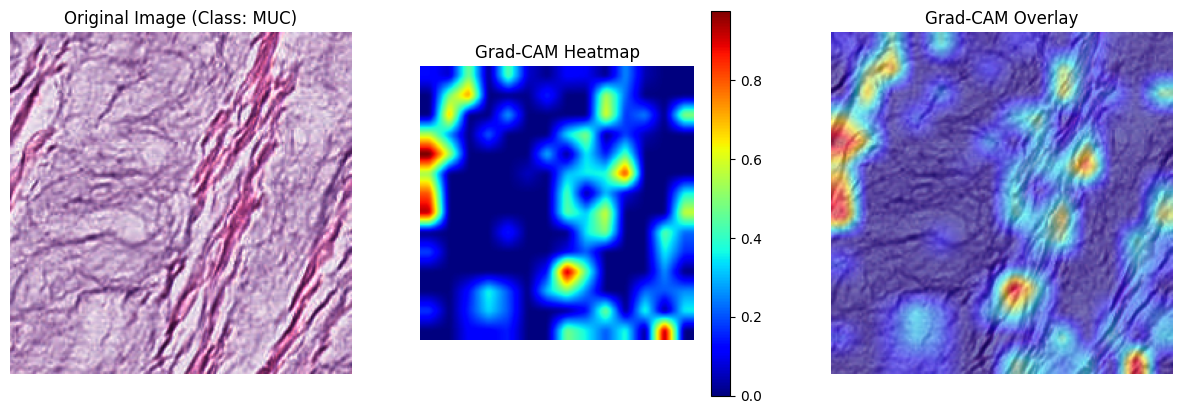

Grad-CAM for class MUC saved to gradcam_outputs/gradcam_class_MUC.png


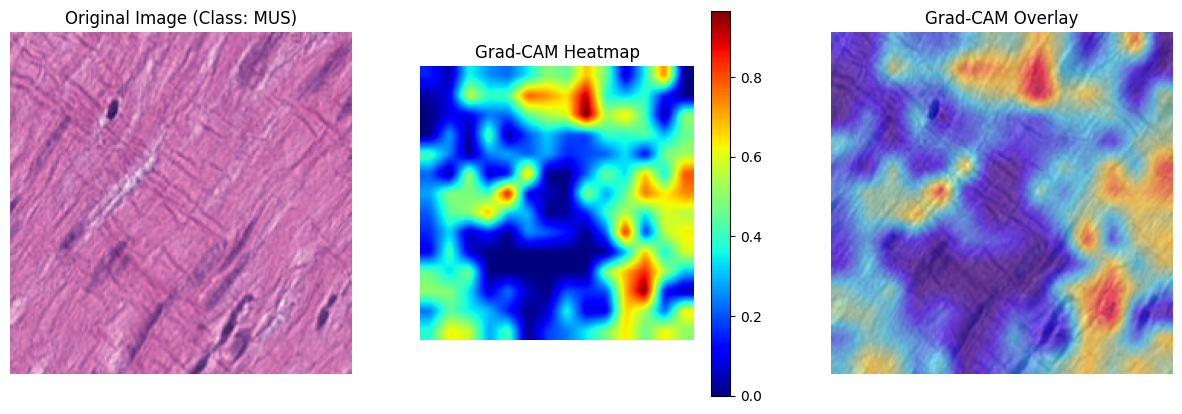

Grad-CAM for class MUS saved to gradcam_outputs/gradcam_class_MUS.png


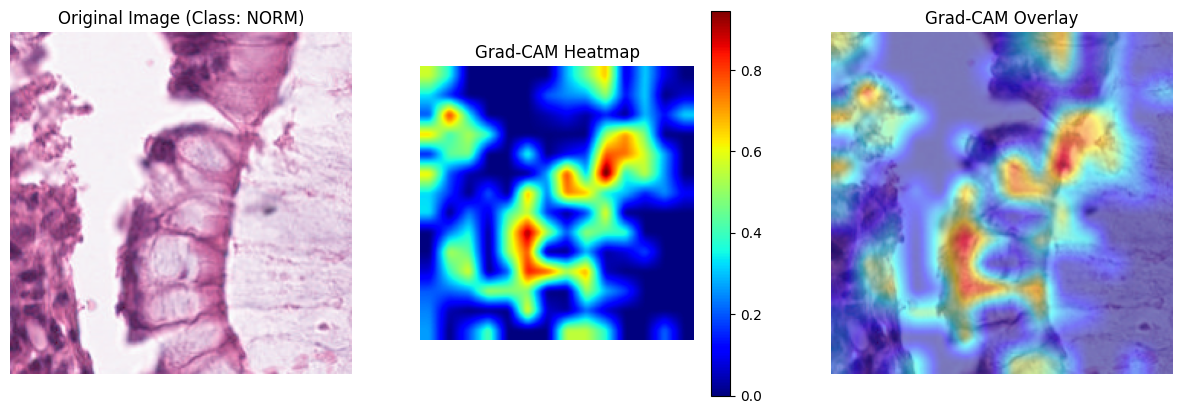

Grad-CAM for class NORM saved to gradcam_outputs/gradcam_class_NORM.png


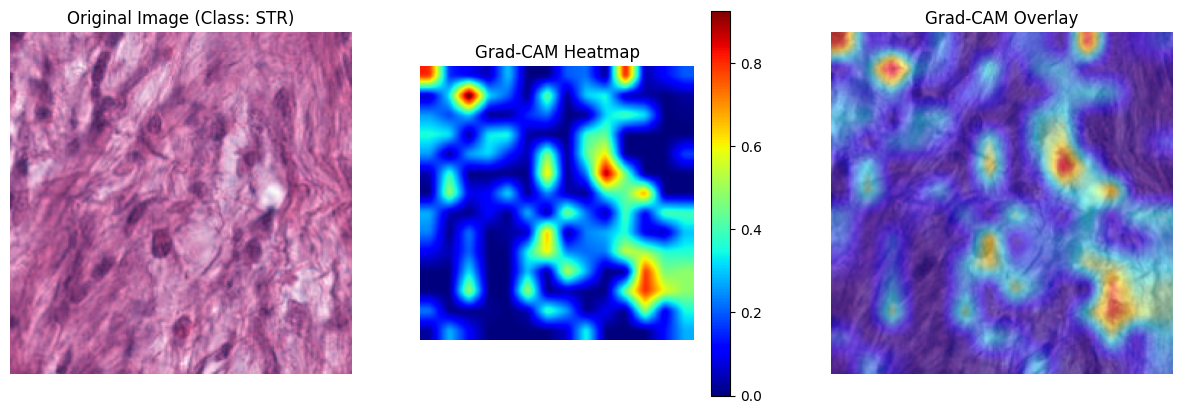

Grad-CAM for class STR saved to gradcam_outputs/gradcam_class_STR.png


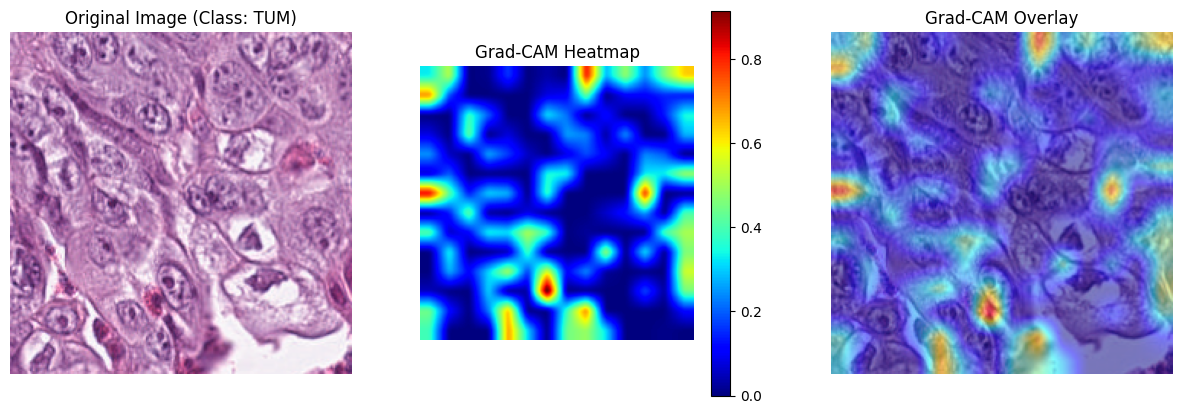

Grad-CAM for class TUM saved to gradcam_outputs/gradcam_class_TUM.png


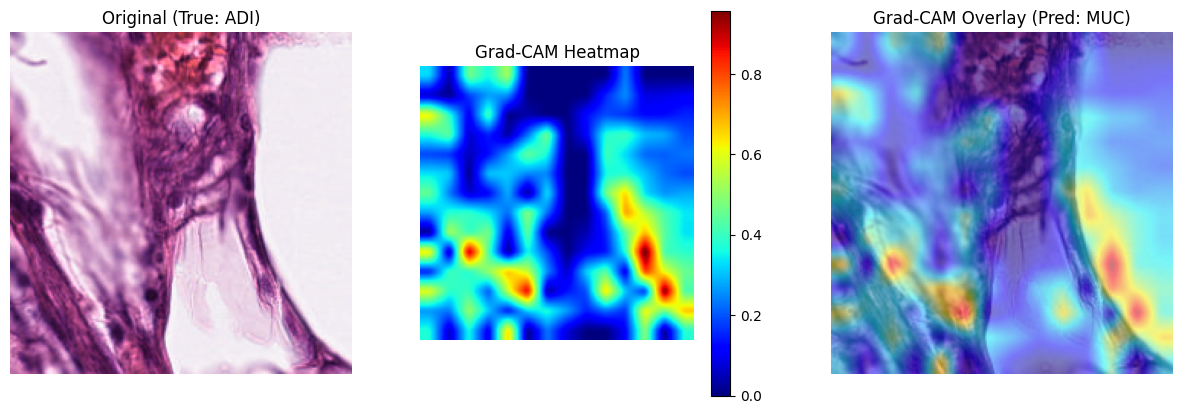

Grad-CAM for incorrect ADI (predicted: MUC) saved to gradcam_incorrect/gradcam_incorrect_ADI_pred_MUC.png
No incorrect predictions found for class BACK
No incorrect predictions found for class DEB
No incorrect predictions found for class LYM


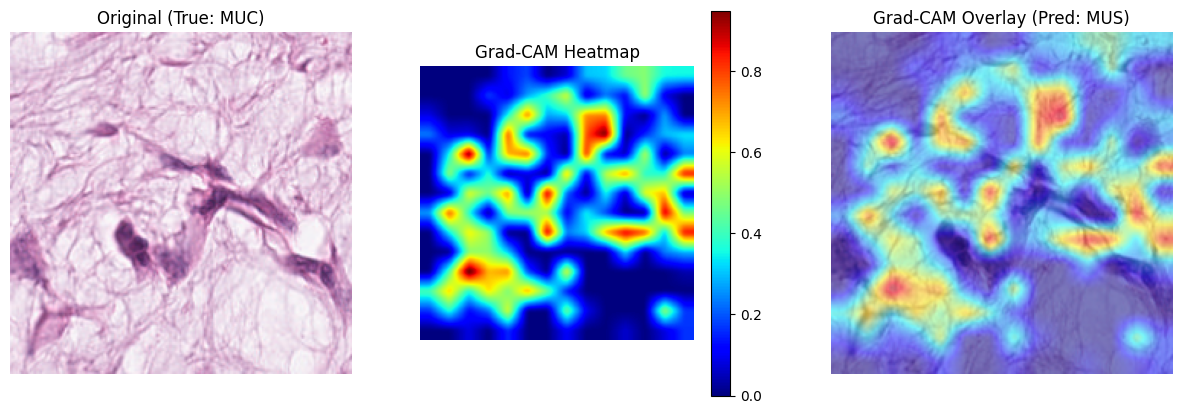

Grad-CAM for incorrect MUC (predicted: MUS) saved to gradcam_incorrect/gradcam_incorrect_MUC_pred_MUS.png


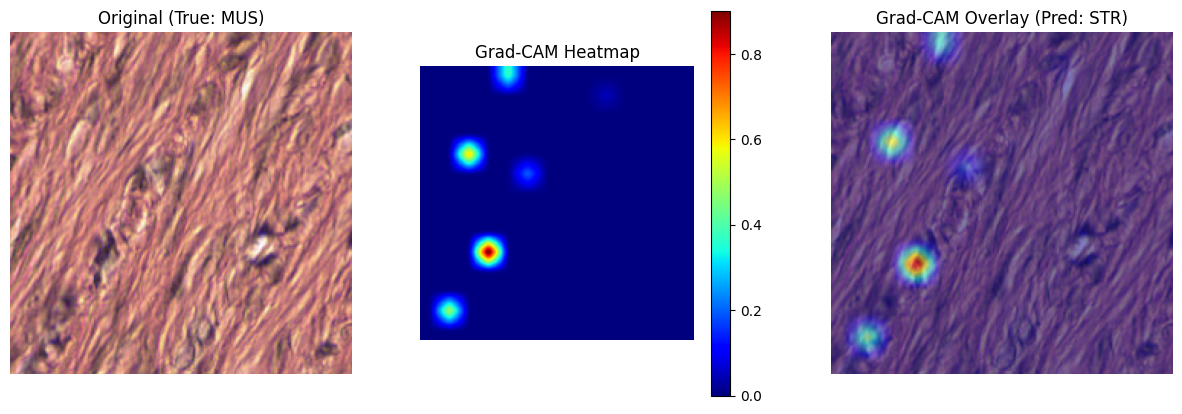

Grad-CAM for incorrect MUS (predicted: STR) saved to gradcam_incorrect/gradcam_incorrect_MUS_pred_STR.png


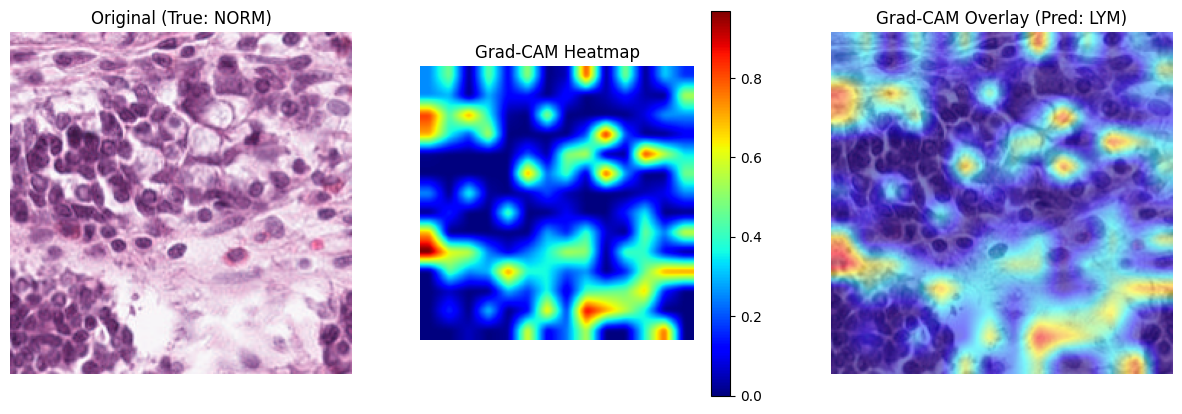

Grad-CAM for incorrect NORM (predicted: LYM) saved to gradcam_incorrect/gradcam_incorrect_NORM_pred_LYM.png


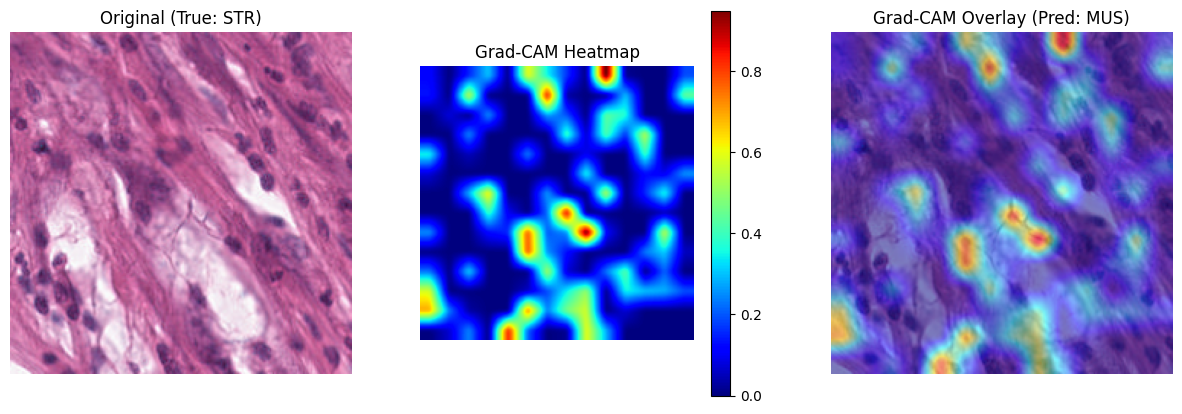

Grad-CAM for incorrect STR (predicted: MUS) saved to gradcam_incorrect/gradcam_incorrect_STR_pred_MUS.png


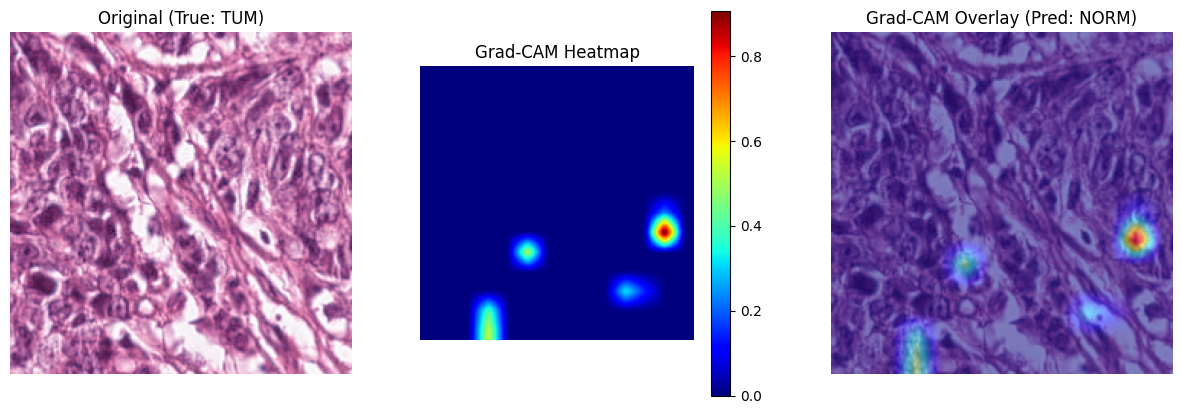

Grad-CAM for incorrect TUM (predicted: NORM) saved to gradcam_incorrect/gradcam_incorrect_TUM_pred_NORM.png


In [ ]:
import os
import sys
import random
import numpy as np
from pathlib import Path
from typing import Optional, Tuple, List, Dict, Any

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import transforms, datasets
from torchvision.models import swin_t, Swin_T_Weights
from PIL import Image
import matplotlib.pyplot as plt

# Import Grad-CAM dependencies
try:
    from pytorch_grad_cam import GradCAM
    from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
    from pytorch_grad_cam.utils.image import show_cam_on_image
except ImportError:
    print("Error: pytorch-grad-cam not installed. Install with: pip install grad-cam")
    sys.exit(1)

# Optional scipy for smoothing
try:
    from scipy import ndimage
    SCIPY_AVAILABLE = True
except ImportError:
    SCIPY_AVAILABLE = False
    print("Warning: scipy not available. Grad-CAM smoothing will be disabled.")


class SwinModelWrapper(nn.Module):
    """
    Wrapper for Swin Transformer to ensure compatibility with Grad-CAM
    """
    def __init__(self, model):
        super(SwinModelWrapper, self).__init__()
        self.model = model

    def forward(self, x):
        return self.model(x)


class SwinGradCAM:

    def __init__(self, model: nn.Module, device: torch.device = None):
        self.model = model
        self.device = device or torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self.model.to(self.device).eval()

        # Data preprocessing transform
        self.transform = transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))
        ])

        # Get target layer
        self.target_layer = self._get_target_layer()

        # Initialize Grad-CAM
        self.wrapper = SwinModelWrapper(self.model)
        self.cam = GradCAM(
            model=self.wrapper,
            target_layers=[self.target_layer],
            reshape_transform=self._reshape_transform_swin
        )

    def _reshape_transform_swin(self, x: torch.Tensor) -> torch.Tensor:
        if x.dim() == 4:
            B, H, W, C = x.shape

            # Check if this is in (B, H, W, C) format (Swin Transformer style)
            # vs (B, C, H, W) format (CNN style)
            if C > max(H, W):  # Likely (B, H, W, C) format
                return x.permute(0, 3, 1, 2).contiguous()
            else:
                return x

        if x.dim() != 3:
            return x

        # For Swin Transformer, the sequence length corresponds to spatial patches
        B, L, C = x.shape

        # Calculate the spatial dimensions based on the sequence length
        # For Swin-T with 224x224 input at different stages:
        # Stage 1 (after conv): 56x56 = 3136 patches
        # Stage 2 (after 1st merge): 28x28 = 784 patches
        # Stage 3 (after 2nd merge): 14x14 = 196 patches
        # Stage 4 (after 3rd merge): 7x7 = 49 patches

        if L == 3136:  # 56x56 patches
            H = W = 56
        elif L == 784:   # 28x28 patches
            H = W = 28
        elif L == 196:   # 14x14 patches
            H = W = 14
        elif L == 49:    # 7x7 patches
            H = W = 7
        else:
            # Try to find the closest perfect square
            sqrt_L = int(L ** 0.5)
            if sqrt_L * sqrt_L == L:
                H = W = sqrt_L
            else:
                # Find the best rectangular approximation
                # Try common Swin Transformer resolutions
                possible_dims = [(7, 7), (14, 14), (28, 28), (56, 56)]
                best_match = None
                min_diff = float('inf')

                for h, w in possible_dims:
                    diff = abs(h * w - L)
                    if diff < min_diff:
                        min_diff = diff
                        best_match = (h, w)

                if best_match and min_diff <= L * 0.1:  # Within 10% tolerance
                    H, W = best_match
                    # Pad or truncate if needed
                    target_L = H * W
                    if target_L != L:
                        if target_L < L:
                            x = x[:, :target_L, :]
                        else:
                            pad_size = target_L - L
                            x = torch.nn.functional.pad(x, (0, 0, 0, pad_size), value=0)
                        L = target_L
                else:
                    # Last resort: force square
                    H = W = int(L ** 0.5)
                    target_L = H * W
                    if target_L != L:
                        x = x[:, :target_L, :]

        # Reshape to spatial format: (B, H, W, C) -> (B, C, H, W)
        try:
            x_reshaped = x.view(B, H, W, C).permute(0, 3, 1, 2).contiguous()
            return x_reshaped
        except Exception as e:
            # Emergency fallback - try to make it work somehow
            sqrt_L = int((x.shape[1]) ** 0.5)
            H = W = sqrt_L
            x_truncated = x[:, :sqrt_L*sqrt_L, :]
            x_reshaped = x_truncated.view(B, H, W, C).permute(0, 3, 1, 2).contiguous()
            return x_reshaped

    def _get_target_layer(self) -> nn.Module:
        """
        Get the best target layer for Grad-CAM in Swin Transformer

        Returns:
            Target layer for Grad-CAM
        """
        try:
            if hasattr(self.model, 'features'):
                # Method 1: Try different stages for better visualization
                # Start with earlier stages that might have better spatial resolution

                # Try Stage 3 (14x14 resolution) - good balance of features and resolution
                try:
                    stage3 = self.model.features[5]  # Stage 3
                    if hasattr(stage3, '__getitem__') and len(stage3) > 1:
                        last_block = stage3[1] if len(stage3) > 1 else stage3[0]
                        if hasattr(last_block, 'norm2'):
                            return last_block.norm2
                except Exception:
                    pass

                # Try Stage 2 (28x28 resolution) - even better spatial resolution
                try:
                    stage2 = self.model.features[3]  # Stage 2
                    if hasattr(stage2, '__getitem__') and len(stage2) > 1:
                        last_block = stage2[1] if len(stage2) > 1 else stage2[0]
                        if hasattr(last_block, 'norm2'):
                            return last_block.norm2
                except Exception:
                    pass

                # Try the final stage (Stage 4) as fallback
                try:
                    last_stage = self.model.features[7]  # Last stage (stage 4)
                    if hasattr(last_stage, '__getitem__') and len(last_stage) > 1:
                        last_block = last_stage[1]  # Last block in the stage
                        if hasattr(last_block, 'norm2'):
                            return last_block.norm2
                except Exception:
                    pass

                # Try the global norm layer (before pooling)
                try:
                    if hasattr(self.model, 'norm'):
                        return self.model.norm
                except Exception:
                    pass

                # Method 3: Search through all layers systematically
                all_norm2_layers = []
                for name, module in self.model.named_modules():
                    if isinstance(module, torch.nn.LayerNorm) and 'norm2' in name:
                        all_norm2_layers.append((name, module))

                if all_norm2_layers:
                    # Prefer layers from earlier stages for better spatial resolution
                    for name, module in all_norm2_layers:
                        if 'features.3' in name or 'features.5' in name:  # Stage 2 or 3
                            return module

                    # Fallback to any norm2 layer
                    return all_norm2_layers[0][1]

            raise RuntimeError("Could not find suitable target layer")

        except Exception as e:
            raise RuntimeError(f"Could not locate a suitable target layer for Swin-T: {e}")

    def _denormalize(self, tensor: torch.Tensor) -> np.ndarray:

        mean = np.array([0.485, 0.456, 0.406])
        std = np.array([0.229, 0.224, 0.225])
        tensor = tensor.detach().cpu().numpy().transpose((1, 2, 0))
        tensor = std * tensor + mean
        tensor = np.clip(tensor, 0, 1)
        return tensor

    def _smooth_gradcam(self, cam: np.ndarray, sigma: float = 1.5) -> np.ndarray:

        if SCIPY_AVAILABLE:
            return ndimage.gaussian_filter(cam, sigma=sigma)
        else:
            return cam

    def generate_gradcam(self, input_tensor: torch.Tensor, target_class: int,
                        smooth: bool = True) -> Tuple[np.ndarray, np.ndarray]:

        targets = [ClassifierOutputTarget(int(target_class))]

        # Get raw CAM
        grayscale_cam = self.cam(input_tensor=input_tensor, targets=targets)[0, :]

        # Apply smoothing if requested
        if smooth:
            grayscale_cam = self._smooth_gradcam(grayscale_cam)

        # Denormalize input for visualization
        input_image = self._denormalize(input_tensor[0])

        return input_image, grayscale_cam

    def visualize_single_image(self, image_path: str, target_class: int = None,
                             save_path: str = None, smooth: bool = True) -> None:

        # Load and preprocess image
        image = Image.open(image_path).convert('RGB')
        input_tensor = self.transform(image).unsqueeze(0).to(self.device)

        # Auto-predict class if not provided
        if target_class is None:
            with torch.no_grad():
                output = self.model(input_tensor)
                target_class = output.argmax(1).item()

        # Generate Grad-CAM
        input_image, grayscale_cam = self.generate_gradcam(input_tensor, target_class, smooth)

        # Create overlay
        visualization = show_cam_on_image(input_image, grayscale_cam, use_rgb=True)

        # Plot results
        plt.figure(figsize=(15, 5))
        plt.subplot(1, 3, 1)
        plt.imshow(input_image)
        plt.title(f"Original Image (Class: {target_class})")
        plt.axis('off')

        plt.subplot(1, 3, 2)
        plt.imshow(grayscale_cam, cmap='jet')
        plt.title("Grad-CAM Heatmap")
        plt.axis('off')
        plt.colorbar()

        plt.subplot(1, 3, 3)
        plt.imshow(visualization)
        plt.title("Grad-CAM Overlay")
        plt.axis('off')

        if save_path:
            plt.savefig(save_path, format='png', dpi=300, bbox_inches='tight')
            print(f"Visualization saved to {save_path}")

        plt.show()

    def generate_per_class_visualization(self, dataloader: DataLoader, class_to_idx: Dict[str, int],
                                       save_dir: str = "gradcam_outputs", smooth: bool = True) -> None:

        os.makedirs(save_dir, exist_ok=True)

        # Find one correctly predicted sample per class
        correct_samples = {label: None for label in class_to_idx.values()}

        self.model.eval()
        with torch.no_grad():
            for inputs, labels in dataloader:
                inputs, labels = inputs.to(self.device), labels.to(self.device)
                outputs = self.model(inputs)
                _, preds = torch.max(outputs, 1)

                for i in range(inputs.size(0)):
                    label = int(labels[i].item())
                    if preds[i].item() == label and correct_samples[label] is None:
                        correct_samples[label] = (inputs[i].unsqueeze(0), label)

                if all(v is not None for v in correct_samples.values()):
                    break

        # Generate visualizations
        inv_class_to_idx = {v: k for k, v in class_to_idx.items()}

        for label, sample in correct_samples.items():
            if sample is None:
                continue

            input_tensor, label_idx = sample
            input_image, grayscale_cam = self.generate_gradcam(input_tensor, label_idx, smooth)

            # Create overlay
            visualization = show_cam_on_image(input_image, grayscale_cam, use_rgb=True)

            class_name = inv_class_to_idx.get(int(label_idx), str(label_idx))

            # Plot and save
            plt.figure(figsize=(15, 5))
            plt.subplot(1, 3, 1)
            plt.imshow(input_image)
            plt.title(f"Original Image (Class: {class_name})")
            plt.axis('off')

            plt.subplot(1, 3, 2)
            plt.imshow(grayscale_cam, cmap='jet')
            plt.title("Grad-CAM Heatmap")
            plt.axis('off')
            plt.colorbar()

            plt.subplot(1, 3, 3)
            plt.imshow(visualization)
            plt.title("Grad-CAM Overlay")
            plt.axis('off')

            save_path = os.path.join(save_dir, f"gradcam_class_{class_name}.png")
            plt.savefig(save_path, format='png', dpi=300, bbox_inches='tight')
            plt.show()

            print(f"Grad-CAM for class {class_name} saved to {save_path}")

    def analyze_incorrect_predictions(self, dataloader: DataLoader, class_to_idx: Dict[str, int],
                                    save_dir: str = "gradcam_incorrect", smooth: bool = True) -> None:

        os.makedirs(save_dir, exist_ok=True)

        # Find incorrect predictions
        incorrect_samples = {label: None for label in class_to_idx.values()}

        self.model.eval()
        with torch.no_grad():
            for inputs, labels in dataloader:
                inputs, labels = inputs.to(self.device), labels.to(self.device)
                outputs = self.model(inputs)
                _, preds = torch.max(outputs, 1)

                for i in range(inputs.size(0)):
                    true_label = int(labels[i].item())
                    pred_label = int(preds[i].item())

                    if pred_label != true_label and incorrect_samples[true_label] is None:
                        incorrect_samples[true_label] = (inputs[i].unsqueeze(0), pred_label, true_label)

        # Generate visualizations for incorrect predictions
        inv_class_to_idx = {v: k for k, v in class_to_idx.items()}

        for true_label, sample in incorrect_samples.items():
            if sample is None:
                true_class = inv_class_to_idx.get(int(true_label), str(true_label))
                print(f"No incorrect predictions found for class {true_class}")
                continue

            input_tensor, pred_label, _ = sample

            # Generate Grad-CAM for the predicted class (what the model focused on)
            input_image, grayscale_cam = self.generate_gradcam(input_tensor, pred_label, smooth)

            # Create overlay
            visualization = show_cam_on_image(input_image, grayscale_cam, use_rgb=True)

            true_class = inv_class_to_idx.get(int(true_label), str(true_label))
            pred_class = inv_class_to_idx.get(int(pred_label), str(pred_label))

            # Plot and save
            plt.figure(figsize=(15, 5))
            plt.subplot(1, 3, 1)
            plt.imshow(input_image)
            plt.title(f"Original (True: {true_class})")
            plt.axis('off')

            plt.subplot(1, 3, 2)
            plt.imshow(grayscale_cam, cmap='jet')
            plt.title("Grad-CAM Heatmap")
            plt.axis('off')
            plt.colorbar()

            plt.subplot(1, 3, 3)
            plt.imshow(visualization)
            plt.title(f"Grad-CAM Overlay (Pred: {pred_class})")
            plt.axis('off')

            save_path = os.path.join(save_dir, f"gradcam_incorrect_{true_class}_pred_{pred_class}.png")
            plt.savefig(save_path, format='png', dpi=300, bbox_inches='tight')
            plt.show()

            print(f"Grad-CAM for incorrect {true_class} (predicted: {pred_class}) saved to {save_path}")


def load_swin_model(model_path: str, num_classes: int, device: torch.device = None) -> nn.Module:

    device = device or torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    # Create model architecture
    weights = Swin_T_Weights.IMAGENET1K_V1
    model = swin_t(weights=weights)
    model.head = nn.Linear(model.head.in_features, num_classes)

    # Load checkpoint
    checkpoint = torch.load(model_path, map_location=device)
    if 'model_state' in checkpoint:
        model.load_state_dict(checkpoint['model_state'])
    else:
        model.load_state_dict(checkpoint)

    return model.to(device)


def main():

    # Configuration
    MODEL_PATH = "/workspace/SD/model_9_best.pth"  # Update this path
    NUM_CLASSES = 9
    DATA_DIR = "/workspace/SD/crc-val-he-7k/CRC-VAL-HE-7K"  # Update this path

    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Using device: {device}")

    # Load model
    try:
        model = load_swin_model(MODEL_PATH, NUM_CLASSES, device)
        print("Model loaded successfully")
    except Exception as e:
        print(f"Error loading model: {e}")
        return

    # Initialize Grad-CAM
    grad_cam = SwinGradCAM(model, device)

    # Load dataset for visualization
    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))
    ])

    try:
        dataset = datasets.ImageFolder(DATA_DIR, transform=transform)
        dataloader = torch.utils.data.DataLoader(dataset, batch_size=32, shuffle=False)
        print(f"Dataset loaded with {len(dataset)} images")

        # Generate per-class visualizations
        grad_cam.generate_per_class_visualization(dataloader, dataset.class_to_idx)

        # Analyze incorrect predictions
        grad_cam.analyze_incorrect_predictions(dataloader, dataset.class_to_idx)

    except Exception as e:
        print(f"Error loading dataset: {e}")


if __name__ == "__main__":
    main()
